# CS 6220 — Homework 2

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

## Part 1: Data Generator

`generate_noisy_dataset` samples `x` uniformly from `x_range`, adds a column `f_i(x)` for each function in `functions`, and computes `y = f(x) + noise`, where the noise is drawn uniformly from `[-ε, ε]`.

It returns the input attributes `X` (columns `x, f_1(x), …, f_d(x)`) and the label `y` separately, which is the format scikit-learn expects.

In [2]:
def generate_noisy_dataset(functions, true_function, x_range, n_samples, noise, seed=None):
    rng = np.random.default_rng(seed)
    x = rng.uniform(x_range[0], x_range[1], size=n_samples)

    # input attributes: x, f_1(x), ..., f_d(x)
    X = pd.DataFrame({'x': x})
    for i, f in enumerate(functions, start=1):
        X[f'f_{i}(x)'] = [f(v) for v in x]

    # output: y = f(x) + noise, noise ~ Uniform[-noise, noise]
    eps = rng.uniform(-noise, noise, size=n_samples)
    y = pd.Series([true_function(v) for v in x] + eps, name='y')

    return X, y

Example from the handout: functions `[x², x³]`, true function `f(x) = log(x)`, x-range `[0.0, 1.0]`, 10 samples, noise level 0.1.

In [3]:
X, y = generate_noisy_dataset(
    functions=[lambda x: x**2, lambda x: x**3],
    true_function=np.log,
    x_range=(0.0, 1.0),
    n_samples=10,
    noise=0.1,
    seed=42,
)
pd.concat([X, y], axis=1)

,x,f_1(x),f_2(x),y
0,0.773956,0.599008,0.463606,-0.282081
1,0.438878,0.192614,0.084534,-0.738180
2,0.858598,0.737190,0.632950,-0.123682
3,0.697368,0.486322,0.339146,-0.295890
4,0.094177,0.008869,0.000835,-2.373893
5,0.975622,0.951839,0.928635,-0.079232
6,0.761140,0.579334,0.440954,-0.262021
7,0.786064,0.617897,0.485707,-0.327953
8,0.128114,0.016413,0.002103,-1.989311
9,0.450386,0.202847,0.091360,-0.771318


In [4]:
# sanity check: every y should be within ε of the true function value
print((y - np.log(X['x'])).abs().max() <= 0.1)

True


### Train/test split

80% training, 20% testing. `random_state` is fixed so repeated experiments on the same dataset always use the same partitioning.

In [5]:
def split_dataset(X, y):
    return train_test_split(X, y, test_size=0.2, random_state=42)

X_train, X_test, y_train, y_test = split_dataset(X, y)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(8, 3) (2, 3) (8,) (2,)


## Part 2: Linear Regression

Records are rows, so the augmented design matrix is `n × (d+1)` with the column of 1s first, and β[0] is the intercept.

In [6]:
def add_intercept(X):
    X = np.asarray(X, dtype=float)
    return np.column_stack([np.ones(X.shape[0]), X])

### Training

In [7]:
def fit(X_train, y_train):
    # 1. convert the training data to matrix X (with the column of 1s) and vector Y
    X = add_intercept(X_train)
    Y = np.asarray(y_train, dtype=float)

    # 2. beta = (X^T X)^-1 X^T Y
    beta = np.linalg.inv(X.T @ X) @ X.T @ Y

    # 3. output the weight vector
    return beta

### Prediction

In [8]:
def predict(beta, X_test):
    # augment the test data with the column of 1s, then y_pred = beta · x for each record
    return add_intercept(X_test) @ beta

### Evaluation

In [9]:
def evaluate_model(y_pred, y_true):
    y_pred = np.asarray(y_pred, dtype=float)
    y_true = np.asarray(y_true, dtype=float)
    # RMSE: total squared loss / number of records, then the square root
    return np.sqrt(np.sum((y_true - y_pred) ** 2) / len(y_true))

### Example

Same setup as the Part 1 example (features `x, x², x³`, true function `log(x)`, ε = 0.1), with 200 samples.

In [10]:
X, y = generate_noisy_dataset(
    functions=[lambda x: x**2, lambda x: x**3],
    true_function=np.log,
    x_range=(0.0, 1.0),
    n_samples=200,
    noise=0.1,
    seed=42,
)
X_train, X_test, y_train, y_test = split_dataset(X, y)

beta = fit(X_train, y_train)
print('beta:', beta)
print(f"Train RMSE: {evaluate_model(predict(beta, X_train), y_train):.4f}")
print(f"Test RMSE:  {evaluate_model(predict(beta, X_test), y_test):.4f}")

beta: [ -3.59568551  12.97206512 -18.820117     9.66427464]
Train RMSE: 0.1558
Test RMSE:  0.1571


## Part 3: Regression Tree

`fit(dataset, min_records)` builds the tree with recursive binary splits:

- Start with all training records in the root node.
- If a node has fewer than `min_records` records, it becomes a leaf that predicts the mean of its y-values.
- Otherwise, for every input attribute A (`x`, plus `f_i(x)` columns if present), sort the records on A and try every split point s at the midpoint between consecutive distinct A-values. Records with A ≤ s go left and the rest go right. Each split is scored by the total SSE of the two children (squared differences between each y and its child's mean).
- Keep the split with the lowest SSE, store (attribute, split point), and recurse on both children.
- Hard stop (leaf) if no split is possible: all y-values in the node are identical, or all records have identical inputs.

`dataset` is the `(X, y)` pair returned by `generate_noisy_dataset` (or its training part).

In [11]:
def sse(y):
    # sum of squared differences between each y and the mean
    return np.sum((y - y.mean()) ** 2)


class Node:
    def __init__(self, value=None, attribute=None, split=None, left=None, right=None):
        self.value = value          # leaf: mean of the y-values in the node
        self.attribute = attribute  # internal node: index of the attribute A
        self.split = split          # internal node: split point s
        self.left = left            # records with A <= s
        self.right = right          # records with A > s

    def is_leaf(self):
        return self.left is None

In [12]:
class RegressionTree:
    def fit(self, dataset, min_records):
        X, y = dataset
        self.columns = list(X.columns)
        self.min_records = min_records
        self.train_x, self.train_y = X['x'].to_numpy(), np.asarray(y, dtype=float)
        self.root = self._build(np.asarray(X, dtype=float), np.asarray(y, dtype=float))
        return self

    def _build(self, X, y):
        # too few records to split: leaf predicting the mean
        if len(y) < self.min_records:
            return Node(value=y.mean())

        best = self._best_split(X, y)
        # hard stop: no split possible (pure node or duplicate inputs)
        if best is None:
            return Node(value=y.mean())

        attribute, split = best
        left = X[:, attribute] <= split
        return Node(attribute=attribute, split=split,
                    left=self._build(X[left], y[left]),
                    right=self._build(X[~left], y[~left]))

    def _best_split(self, X, y):
        if np.all(y == y[0]):
            return None

        best, best_sse = None, np.inf
        for a in range(X.shape[1]):
            # sorted distinct values of attribute A, candidate splits at the midpoints
            values = np.unique(X[:, a])
            for s in (values[:-1] + values[1:]) / 2:
                left = X[:, a] <= s
                total = sse(y[left]) + sse(y[~left])
                if total < best_sse:
                    best, best_sse = (a, s), total

        # None if every attribute has a single distinct value
        return best

    def predict(self, X):
        if isinstance(X, pd.DataFrame):
            X = X[self.columns]
        X = np.asarray(X, dtype=float)
        return np.array([self._predict_one(row) for row in X])

    def _predict_one(self, row):
        node = self.root
        while not node.is_leaf():
            node = node.left if row[node.attribute] <= node.split else node.right
        return node.value

    def n_leaves(self, node=None):
        node = node or self.root
        return 1 if node.is_leaf() else self.n_leaves(node.left) + self.n_leaves(node.right)

    def visualize(self, functions=(), true_function=None, n_points=2000, ax=None):
        # functions must be the same list used to generate the training data,
        # so the f_i(x) columns can be computed for a dense grid of x-values.
        # ax: optional matplotlib axes to draw on (e.g. one panel of a grid)
        if len(functions) != len(self.columns) - 1:
            raise ValueError('pass the same functions used to generate the training data')

        grid = np.linspace(self.train_x.min(), self.train_x.max(), n_points)
        X_grid = pd.DataFrame({'x': grid})
        for i, f in enumerate(functions, start=1):
            X_grid[f'f_{i}(x)'] = [f(v) for v in grid]
        y_grid = self.predict(X_grid)

        show = ax is None
        if show:
            fig, ax = plt.subplots(figsize=(9, 5))
        ax.scatter(self.train_x, self.train_y, s=12, alpha=0.5, label='training data')

        # split points: x-positions where the tree's prediction changes
        splits = ((grid[:-1] + grid[1:]) / 2)[np.diff(y_grid) != 0]
        for i, s in enumerate(splits):
            ax.axvline(s, color='gray', linestyle=':', linewidth=0.8, alpha=0.6,
                       label='split points' if i == 0 else None)

        if true_function is not None:
            ax.plot(grid, [true_function(v) for v in grid], 'g--', label='true f(x)')
        ax.plot(grid, y_grid, 'r', linewidth=2, label='tree prediction')

        ax.set_xlabel('x')
        ax.set_ylabel('y')
        ax.set_title(f'Regression tree (min_records={self.min_records}, {self.n_leaves()} leaves)')
        ax.legend()
        if show:
            plt.show()

### Example

Same dataset and split as the Part 2 example (attributes `x, x², x³`, true function `log(x)`).

Train RMSE: 0.1474
Test RMSE:  0.1143


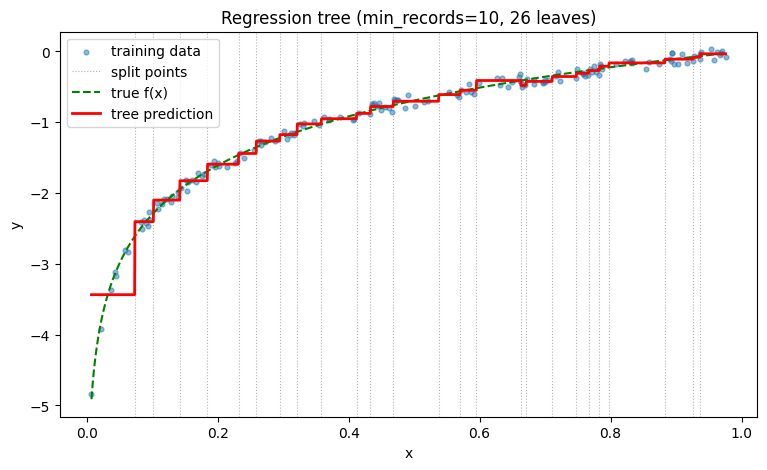

In [13]:
functions = [lambda x: x**2, lambda x: x**3]

tree = RegressionTree().fit((X_train, y_train), min_records=10)
print(f"Train RMSE: {evaluate_model(tree.predict(X_train), y_train):.4f}")
print(f"Test RMSE:  {evaluate_model(tree.predict(X_test), y_test):.4f}")

tree.visualize(functions, true_function=np.log)